# 🇨🇲 Projet 02 — Mobile Money Analytics Cameroon

## Workflow

**SQLite → SQL → Python/Pandas → Visualisation → Power BI → Recommandations métier**

Ce projet utilise **10 000 transactions synthétiques**.  
Aucune donnée réelle de MTN, Orange, d'un client ou d'un agent n'est utilisée.

## Problématique

> Comment une plateforme Mobile Money peut-elle améliorer son activité, son revenu net et sa qualité de service grâce aux données ?


# 0. Connexion à SQLite

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Chemin portable : fonctionne depuis notebooks/ ou depuis la racine du dépôt.
_candidates = [
    Path("../data/database/mobile_money_cameroon.db"),
    Path("data/database/mobile_money_cameroon.db"),
]
DB_PATH = next((p.resolve() for p in _candidates if p.exists()), None)
if DB_PATH is None:
    raise FileNotFoundError(
        "Base SQLite introuvable. Lancez le notebook depuis la racine du dépôt ou depuis notebooks/."
    )

con = sqlite3.connect(DB_PATH)
print("Connexion réussie :", DB_PATH)


Connexion réussie : ../data/database/mobile_money_cameroon.db


# PARTIE 1 — SQL

Ici, **SQL réalise l'extraction et les agrégations**. Python sert à envoyer les requêtes et afficher les résultats.


## 1.1 Aperçu — SELECT

In [2]:
query = """
SELECT *
FROM vw_mobile_money_analysis
LIMIT 10;
"""
pd.read_sql_query(query, con)

,transaction_id,datetime_tx,date_tx,year,year_month,hour,day_of_week,operator,transaction_type,channel,city,region,client_segment,agent_type,client_id,agent_id,amount_fcfa,fee_fcfa,agent_commission_fcfa,net_revenue_fcfa,status,failure_reason
0,MM000001,2026-05-29 09:24:06,2026-05-29,2026,2026-05,9,Friday,MTN MoMo,Merchant Payment,Mobile App,Yaoundé,Centre,Particulier,Kiosque,C00905,A0039,13300,50,0,50,Success,None
1,MM000002,2026-04-18 05:24:10,2026-04-18,2026,2026-04,5,Saturday,MTN MoMo,Cash Out,Agent POS,Maroua,Extrême-Nord,Commerçant,Kiosque,C01424,A0122,29400,325,74,251,Success,None
2,MM000003,2025-12-09 16:38:09,2025-12-09,2025,2025-12,16,Tuesday,Orange Money,Bill Payment,Agent POS,Yaoundé,Centre,Particulier,Boutique,C01255,A0040,13400,50,0,50,Success,None
3,MM000004,2025-12-14 13:44:42,2025-12-14,2025,2025-12,13,Sunday,MTN MoMo,Cash In,Agent POS,Bafoussam,Ouest,Particulier,Kiosque,C02390,A0064,7200,0,13,-13,Success,None
4,MM000005,2026-02-07 14:45:17,2026-02-07,2026,2026-02,14,Saturday,MTN MoMo,Airtime/Data,USSD,Bafoussam,Ouest,Particulier,Agence partenaire,C01363,A0071,3800,10,0,10,Success,None
5,MM000006,2024-08-22 17:03:21,2024-08-22,2024,2024-08,17,Thursday,MTN MoMo,Airtime/Data,Mobile App,Douala,Littoral,Commerçant,Boutique,C00750,A0030,6400,10,0,10,Success,None
6,MM000007,2025-08-31 20:56:51,2025-08-31,2025,2025-08,20,Sunday,MTN MoMo,P2P Transfer,USSD,Bafoussam,Ouest,PME,Agence partenaire,C01309,A0071,12100,75,0,75,Success,None
7,MM000008,2025-06-25 16:44:48,2025-06-25,2025,2025-06,16,Wednesday,MTN MoMo,Airtime/Data,Mobile App,Yaoundé,Centre,Commerçant,Kiosque,C02038,A0057,3300,10,0,10,Success,None
8,MM000009,2025-10-01 23:13:50,2025-10-01,2025,2025-10,23,Wednesday,Orange Money,Merchant Payment,Mobile App,Garoua,Nord,Particulier,Super Agent,C00465,A0113,12100,50,0,50,Success,None
9,MM000010,2024-12-15 17:20:04,2024-12-15,2024,2024-12,17,Sunday,MTN MoMo,Cash Out,Agent POS,Bafoussam,Ouest,Particulier,Kiosque,C00521,A0067,25300,275,63,212,Success,None


## 1.2 KPI globaux — COUNT / SUM / AVG

In [3]:
query = """
SELECT
    COUNT(*) AS transactions,
    SUM(CASE WHEN status='Success' THEN 1 ELSE 0 END) AS transactions_reussies,
    ROUND(100.0 * SUM(CASE WHEN status='Success' THEN 1 ELSE 0 END) / COUNT(*), 2) AS taux_succes_pct,
    ROUND(SUM(CASE WHEN status='Success' THEN amount_fcfa ELSE 0 END),0) AS valeur_fcfa,
    ROUND(AVG(CASE WHEN status='Success' THEN amount_fcfa END),0) AS montant_moyen_fcfa,
    SUM(fee_fcfa) AS frais_fcfa,
    SUM(agent_commission_fcfa) AS commissions_agents_fcfa,
    SUM(net_revenue_fcfa) AS revenu_net_fcfa
FROM fact_transactions;
"""
kpi_sql = pd.read_sql_query(query, con)
kpi_sql

,transactions,transactions_reussies,taux_succes_pct,valeur_fcfa,montant_moyen_fcfa,frais_fcfa,commissions_agents_fcfa,revenu_net_fcfa
0,10000,9728,97.28,"226,335,400.00","23,266.00",1299080,281934,1017146


## 1.3 Performance par opérateur — GROUP BY

In [4]:
query = """
SELECT
    operator,
    COUNT(*) AS transactions,
    ROUND(SUM(CASE WHEN status='Success' THEN amount_fcfa ELSE 0 END),0) AS valeur_fcfa,
    SUM(net_revenue_fcfa) AS revenu_net_fcfa,
    ROUND(100.0 * SUM(CASE WHEN status='Success' THEN 1 ELSE 0 END) / COUNT(*),2) AS taux_succes_pct
FROM fact_transactions
GROUP BY operator
ORDER BY valeur_fcfa DESC;
"""
operator_sql = pd.read_sql_query(query, con)
operator_sql

,operator,transactions,valeur_fcfa,revenu_net_fcfa,taux_succes_pct
0,MTN MoMo,5413,"123,210,900.00",535668,97.30
1,Orange Money,4587,"103,124,500.00",481478,97.25


## 1.4 Types de transactions

In [5]:
query = """
SELECT
    transaction_type,
    COUNT(*) AS transactions,
    ROUND(SUM(CASE WHEN status='Success' THEN amount_fcfa ELSE 0 END),0) AS valeur_fcfa,
    ROUND(AVG(CASE WHEN status='Success' THEN amount_fcfa END),0) AS montant_moyen_fcfa,
    SUM(net_revenue_fcfa) AS revenu_net_fcfa
FROM fact_transactions
GROUP BY transaction_type
ORDER BY valeur_fcfa DESC;
"""
type_sql = pd.read_sql_query(query, con)
type_sql

,transaction_type,transactions,valeur_fcfa,montant_moyen_fcfa,revenu_net_fcfa
0,Cash Out,2103,"72,598,900.00","35,623.00",597565
1,P2P Transfer,2394,"59,017,500.00","25,340.00",353500
2,Cash In,1930,"55,829,000.00","29,492.00",-100474
3,Merchant Payment,1394,"19,012,200.00","13,918.00",78600
4,Bill Payment,881,"15,343,000.00","17,945.00",74325
5,Airtime/Data,1298,"4,534,800.00","3,637.00",13630


## 1.5 Villes — GROUP BY

In [6]:
query = """
SELECT
    city,
    COUNT(*) AS transactions,
    ROUND(SUM(CASE WHEN status='Success' THEN amount_fcfa ELSE 0 END),0) AS valeur_fcfa,
    SUM(net_revenue_fcfa) AS revenu_net_fcfa
FROM fact_transactions
GROUP BY city
ORDER BY valeur_fcfa DESC;
"""
city_sql = pd.read_sql_query(query, con)
city_sql

,city,transactions,valeur_fcfa,revenu_net_fcfa
0,Douala,2442,"55,438,900.00",244672
1,Yaoundé,2155,"46,796,300.00",221253
2,Bafoussam,1508,"34,441,800.00",161739
3,Bamenda,1087,"24,564,200.00",106073
4,Garoua,994,"22,979,400.00",101275
5,Dschang,968,"21,257,300.00",96800
6,Maroua,846,"20,857,500.00",85334


## 1.6 Segments clients — JOIN

In [7]:
query = """
SELECT
    c.client_segment,
    COUNT(*) AS transactions,
    COUNT(DISTINCT f.client_id) AS clients_actifs,
    ROUND(SUM(CASE WHEN f.status='Success' THEN f.amount_fcfa ELSE 0 END),0) AS valeur_fcfa,
    ROUND(AVG(CASE WHEN f.status='Success' THEN f.amount_fcfa END),0) AS montant_moyen_fcfa
FROM fact_transactions f
JOIN dim_client c
    ON f.client_id = c.client_id
GROUP BY c.client_segment
ORDER BY valeur_fcfa DESC;
"""
segment_sql = pd.read_sql_query(query, con)
segment_sql

,client_segment,transactions,clients_actifs,valeur_fcfa,montant_moyen_fcfa
0,Particulier,7735,1881,"144,976,700.00","19,253.00"
1,PME,1260,326,"49,813,300.00","40,931.00"
2,Commerçant,1005,251,"31,545,400.00","32,156.00"


## 1.7 Raisons d'échec

In [8]:
query = """
SELECT
    failure_reason,
    COUNT(*) AS echecs
FROM fact_transactions
WHERE status='Failed'
GROUP BY failure_reason
ORDER BY echecs DESC;
"""
fail_sql = pd.read_sql_query(query, con)
fail_sql

,failure_reason,echecs
0,Solde insuffisant,93
1,Timeout réseau,60
2,PIN incorrect,43
3,Plafond dépassé,29
4,Compte destinataire invalide,24
5,Service indisponible,23


## 1.8 Croissance mensuelle — CTE + LAG

In [9]:
query = """
WITH mensuel AS (
    SELECT
        year_month,
        SUM(CASE WHEN status='Success' THEN amount_fcfa ELSE 0 END) AS valeur
    FROM fact_transactions
    GROUP BY year_month
),
evolution AS (
    SELECT
        year_month,
        valeur,
        LAG(valeur) OVER (ORDER BY year_month) AS valeur_prec
    FROM mensuel
)
SELECT
    year_month,
    ROUND(valeur,0) AS valeur_fcfa,
    ROUND(100.0 * (valeur - valeur_prec) / valeur_prec,2) AS croissance_mom_pct
FROM evolution
ORDER BY year_month;
"""
growth_sql = pd.read_sql_query(query, con)
growth_sql.tail(12)

,year_month,valeur_fcfa,croissance_mom_pct
19,2025-08,"7,597,700.00",4.74
20,2025-09,"7,349,200.00",-3.27
21,2025-10,"7,322,600.00",-0.36
22,2025-11,"7,577,800.00",3.49
23,2025-12,"7,536,800.00",-0.54
24,2026-01,"6,695,400.00",-11.16
25,2026-02,"7,252,200.00",8.32
26,2026-03,"8,359,500.00",15.27
27,2026-04,"7,193,300.00",-13.95
28,2026-05,"8,078,200.00",12.30


# PARTIE 2 — Python / Pandas

Nous chargeons maintenant la vue analytique SQL dans Pandas pour approfondir l'analyse.


In [10]:
df = pd.read_sql_query(
    "SELECT * FROM vw_mobile_money_analysis",
    con,
    parse_dates=["datetime_tx", "date_tx"]
)
df.head()


,transaction_id,datetime_tx,date_tx,year,year_month,hour,day_of_week,operator,transaction_type,channel,city,region,client_segment,agent_type,client_id,agent_id,amount_fcfa,fee_fcfa,agent_commission_fcfa,net_revenue_fcfa,status,failure_reason
0,MM000001,2026-05-29 09:24:06,2026-05-29,2026,2026-05,9,Friday,MTN MoMo,Merchant Payment,Mobile App,Yaoundé,Centre,Particulier,Kiosque,C00905,A0039,13300,50,0,50,Success,None
1,MM000002,2026-04-18 05:24:10,2026-04-18,2026,2026-04,5,Saturday,MTN MoMo,Cash Out,Agent POS,Maroua,Extrême-Nord,Commerçant,Kiosque,C01424,A0122,29400,325,74,251,Success,None
2,MM000003,2025-12-09 16:38:09,2025-12-09,2025,2025-12,16,Tuesday,Orange Money,Bill Payment,Agent POS,Yaoundé,Centre,Particulier,Boutique,C01255,A0040,13400,50,0,50,Success,None
3,MM000004,2025-12-14 13:44:42,2025-12-14,2025,2025-12,13,Sunday,MTN MoMo,Cash In,Agent POS,Bafoussam,Ouest,Particulier,Kiosque,C02390,A0064,7200,0,13,-13,Success,None
4,MM000005,2026-02-07 14:45:17,2026-02-07,2026,2026-02,14,Saturday,MTN MoMo,Airtime/Data,USSD,Bafoussam,Ouest,Particulier,Agence partenaire,C01363,A0071,3800,10,0,10,Success,None


## 2.1 Contrôle qualité

In [11]:
print("Dimensions :", df.shape)
print("Doublons transaction_id :", df["transaction_id"].duplicated().sum())
print("Valeurs manquantes hors failure_reason :", int(df.drop(columns=["failure_reason"]).isna().sum().sum()))
print("Période :", df["date_tx"].min().date(), "→", df["date_tx"].max().date())


Dimensions : (10000, 22)
Doublons transaction_id : 0
Valeurs manquantes hors failure_reason : 0
Période : 2024-01-01 → 2026-07-31


## 2.2 KPI Python

In [12]:
success = df["status"].eq("Success")
transactions = len(df)
success_tx = int(success.sum())
value_total = df.loc[success, "amount_fcfa"].sum()
fees = df["fee_fcfa"].sum()
commissions = df["agent_commission_fcfa"].sum()
net_revenue = df["net_revenue_fcfa"].sum()

kpi = pd.DataFrame({
    "KPI": ["Transactions","Transactions réussies","Taux de succès","Valeur traitée","Frais","Commissions agents","Revenu net"],
    "Valeur": [
        f"{transactions:,}",
        f"{success_tx:,}",
        f"{success_tx/transactions:.2%}",
        f"{value_total:,.0f} FCFA",
        f"{fees:,.0f} FCFA",
        f"{commissions:,.0f} FCFA",
        f"{net_revenue:,.0f} FCFA"
    ]
})
kpi


,KPI,Valeur
0,Transactions,"10,000"
1,Transactions réussies,"9,728"
2,Taux de succès,97.28%
3,Valeur traitée,"226,335,400 FCFA"
4,Frais,"1,299,080 FCFA"
5,Commissions agents,"281,934 FCFA"
6,Revenu net,"1,017,146 FCFA"


## 2.3 Performance opérateurs

In [13]:
op_python = (
    df.assign(valeur_reussie=df["amount_fcfa"].where(success, 0))
      .groupby("operator", as_index=False)
      .agg(
          transactions=("transaction_id","count"),
          valeur_fcfa=("valeur_reussie","sum"),
          frais_fcfa=("fee_fcfa","sum"),
          revenu_net_fcfa=("net_revenue_fcfa","sum")
      )
)
op_python


,operator,transactions,valeur_fcfa,frais_fcfa,revenu_net_fcfa
0,MTN MoMo,5413,123210900,687255,535668
1,Orange Money,4587,103124500,611825,481478


## 2.4 Analyse des heures de pointe

In [14]:
hourly = (
    df.groupby("hour", as_index=False)
      .agg(transactions=("transaction_id","count"),
           valeur_fcfa=("amount_fcfa","sum"))
      .sort_values("hour")
)
hourly.head()


,hour,transactions,valeur_fcfa
0,0,142,4401900
1,1,56,1263500
2,2,52,1106600
3,3,37,720200
4,4,46,1109400


## 2.5 Taux d'échec par canal

In [15]:
channel_quality = (
    df.assign(echec=df["status"].eq("Failed").astype(int))
      .groupby("channel", as_index=False)
      .agg(transactions=("transaction_id","count"),
           echecs=("echec","sum"))
)
channel_quality["taux_echec"] = channel_quality["echecs"] / channel_quality["transactions"]
channel_quality.sort_values("taux_echec", ascending=False)


,channel,transactions,echecs,taux_echec
2,USSD,2896,106,0.04
0,Agent POS,5289,128,0.02
1,Mobile App,1815,38,0.02


# PARTIE 3 — Visualisations

## 3.1 Valeur traitée par opérateur

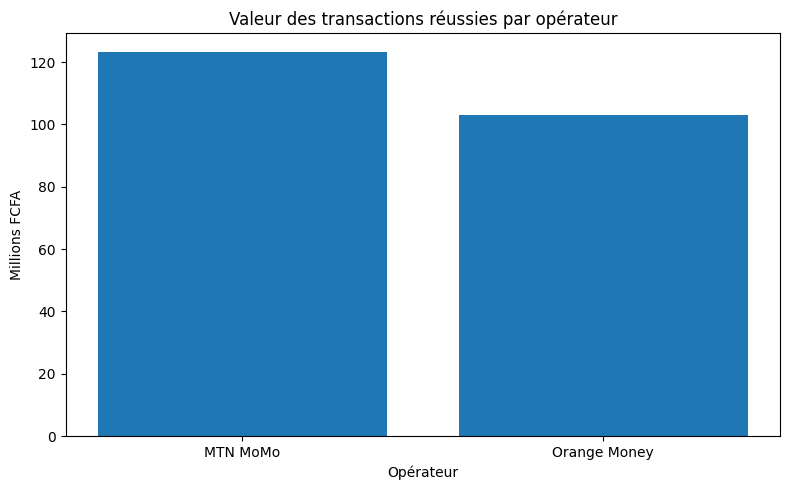

In [16]:
plt.figure(figsize=(8,5))
plt.bar(op_python["operator"], op_python["valeur_fcfa"]/1_000_000)
plt.title("Valeur des transactions réussies par opérateur")
plt.xlabel("Opérateur")
plt.ylabel("Millions FCFA")
plt.tight_layout()
plt.show()


## 3.2 Activité horaire

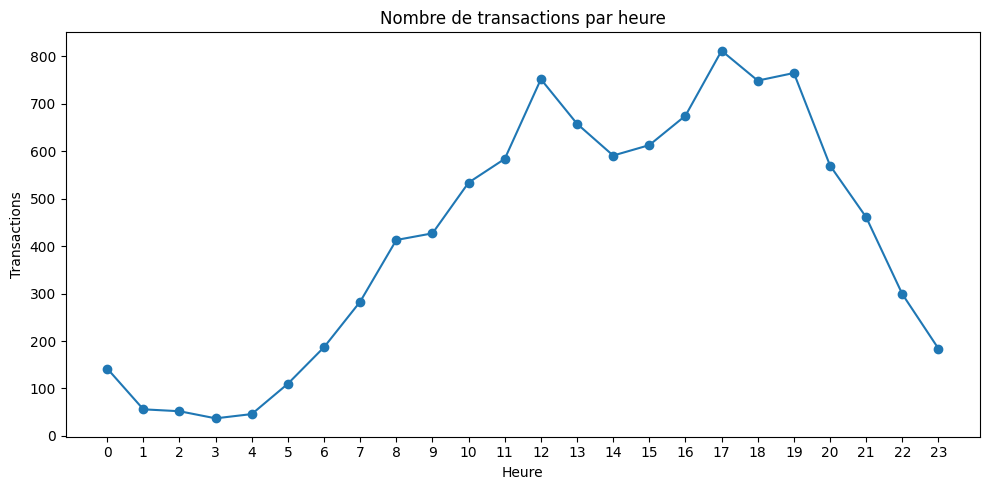

In [17]:
plt.figure(figsize=(10,5))
plt.plot(hourly["hour"], hourly["transactions"], marker="o")
plt.title("Nombre de transactions par heure")
plt.xlabel("Heure")
plt.ylabel("Transactions")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


## 3.3 Échecs par raison

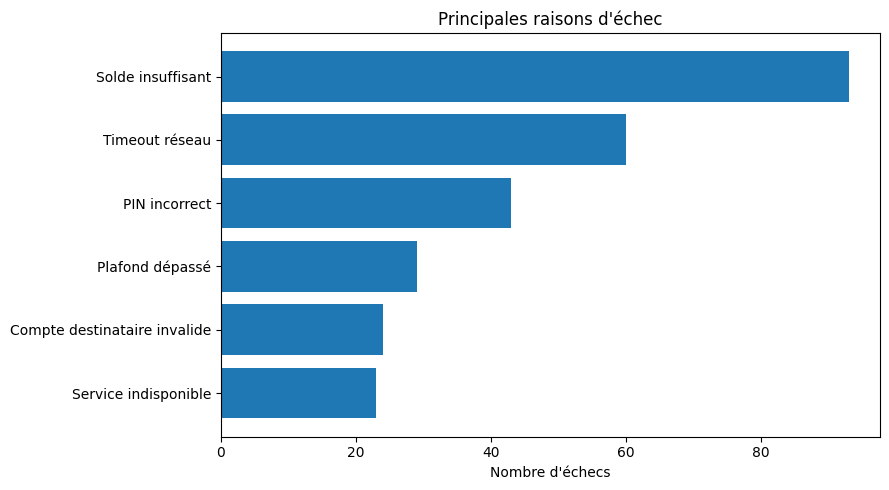

In [18]:
fail_plot = (
    df[df["status"].eq("Failed")]
      .groupby("failure_reason", as_index=False)
      .agg(echecs=("transaction_id","count"))
      .sort_values("echecs", ascending=True)
)
plt.figure(figsize=(9,5))
plt.barh(fail_plot["failure_reason"], fail_plot["echecs"])
plt.title("Principales raisons d'échec")
plt.xlabel("Nombre d'échecs")
plt.tight_layout()
plt.show()


# PARTIE 4 — Recommandations métier

Les analyses doivent conduire à des décisions :

1. **Qualité de service** — réduire les `Timeout réseau` et `Service indisponible`, particulièrement sur les canaux où le taux d'échec est supérieur.
2. **Réseau d'agents** — suivre séparément les volumes, commissions et niveaux d'activité des points agents.
3. **Revenu net** — ne pas analyser uniquement la valeur des transactions : certaines opérations peuvent avoir une forte valeur mais une faible contribution nette.
4. **Canaux digitaux** — suivre la migration USSD → Mobile App et comparer les taux de succès.
5. **Segments** — développer des offres adaptées aux PME et commerçants, qui peuvent afficher des montants moyens plus élevés.
6. **Géographie** — dimensionner le réseau d'agents et l'infrastructure selon les villes et les heures de pointe.
7. **Opérateurs** — les comparaisons MTN MoMo / Orange Money sont propres à ce jeu synthétique et ne constituent pas des parts de marché réelles.


# PARTIE 5 — Power BI

Le rapport Power BI comprend quatre pages :

1. **Executive Overview**
2. **Transactions & Revenue**
3. **Customers & Agents**
4. **Quality & Operations**

Les mesures DAX et le projet `.pbip` sont disponibles dans le dossier `powerbi/`.


In [19]:
con.close()
print("Analyse terminée.")


Analyse terminée.
